# Objective 2 - Weekly sales forecasting

Forecasts eTech's weekly product revenue and compares a set of models against baselines
that cost nothing to run.

**The data.** `01_sales_preprocessing.ipynb` produced a weekly series of 243 ISO weeks
(3 Jan 2022 - 24 Aug 2026) with service lines removed, so this is product revenue only.

**The split.** 80% train / 20% test, taken in time order, never at random - a random split
would let the model see 2026 while predicting 2025.

**The framing.** Every model here stands at the end of the training period and forecasts the
whole test block *blind*. It never sees a test actual, not even from the week before. That
rules out `revenue_lag1` and `revenue_roll4`, which need recent actuals - they are available
only in a one-week-ahead setup, which is a different and much easier problem.

**Scoring.** MAE, RMSE and WAPE. Not MAPE: the quietest test week takes about RM 12,000 and
percentage error on thin weeks dominates the average.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

train_in = pd.read_csv("data/processed/train_weekly.csv", parse_dates=["weekStart"])
test_in  = pd.read_csv("data/processed/test_weekly.csv",  parse_dates=["weekStart"])

weekly = (pd.concat([train_in, test_in], ignore_index=True)
            .sort_values("weekStart").reset_index(drop=True))

assert (weekly.weekStart.diff().dropna().dt.days == 7).all(), "series is not contiguous weekly"
print(f"{len(weekly)} weeks  {weekly.weekStart.min():%Y-%m-%d} -> {weekly.weekStart.max():%Y-%m-%d}")

243 weeks  2022-01-03 -> 2026-08-24


## The 80/20 split

Chronological. The cut falls in September 2025, which has a consequence worth stating
plainly: the 2026 component price shock begins in October 2025, so **the training period
contains none of it**. Every model below is being asked to forecast a structural break it has
never seen. That is the honest test, and it is why the errors are what they are.

In [2]:
cut = int(len(weekly) * 0.8)
train, test = weekly.iloc[:cut].copy(), weekly.iloc[cut:].copy()
y_true = test.revenue.to_numpy()

print(f"TRAIN {len(train):3d} weeks  {train.weekStart.min():%Y-%m-%d} -> {train.weekStart.max():%Y-%m-%d}")
print(f"TEST  {len(test):3d} weeks  {test.weekStart.min():%Y-%m-%d} -> {test.weekStart.max():%Y-%m-%d}")
print()
print(f"train revenue  min RM {train.revenue.min():>9,.0f}   max RM {train.revenue.max():>9,.0f}")
print(f"test  revenue  min RM {test.revenue.min():>9,.0f}   max RM {test.revenue.max():>9,.0f}")
print()
print(f"test weeks below the lowest week ever seen in training: "
      f"{(y_true < train.revenue.min()).sum()} of {len(test)}")

TRAIN 194 weeks  2022-01-03 -> 2025-09-15
TEST   49 weeks  2025-09-22 -> 2026-08-24

train revenue  min RM    21,967   max RM   144,476
test  revenue  min RM    12,119   max RM    82,334

test weeks below the lowest week ever seen in training: 7 of 49


### Why that last number decides which models can work

Seven test weeks are quieter than *any* week in the training data.

A tree-based model predicts the mean of the training values that land in a leaf, so its
output can never go below the smallest target it was trained on. On a series falling this
hard that is not a tuning problem, it is arithmetic - those seven weeks are unreachable.

The fix is not to abandon trees but to give them a stationary target: divide out the trend,
let the tree model what is left, then multiply the trend back in. Both versions are run below
so the difference is visible rather than asserted.

In [3]:
results = []
predictions = {}

def evaluate(name, predicted, note=""):
    p = np.asarray(predicted, dtype=float)
    err = y_true - p
    results.append({
        "model": name,
        "MAE":   np.abs(err).mean(),
        "RMSE":  np.sqrt((err ** 2).mean()),
        "WAPE%": np.abs(err).sum() / y_true.sum() * 100,
        "note":  note,
    })
    predictions[name] = p
    return p

## Baselines

If a model cannot beat these, it has not earned its place in the report.

In [4]:
evaluate("Naive (last train week)",
         np.repeat(train.revenue.iloc[-1], len(test)), "flat line")

evaluate("Mean of last 26 weeks",
         np.repeat(train.revenue.tail(26).mean(), len(test)), "flat line")

evaluate("Seasonal naive (lag 52)",
         test.revenue_lag52.to_numpy(), "same week, last year")

log_trend = np.polyfit(train.t, np.log(train.revenue), 1)
evaluate("Log-linear trend",
         np.exp(np.polyval(log_trend, test.t.to_numpy())), "the bar to beat")

print(pd.DataFrame(results).to_string(index=False))

                  model      MAE     RMSE  WAPE%                 note
Naive (last train week) 21,379.5 24,833.5   49.1            flat line
  Mean of last 26 weeks 18,212.7 21,147.6   41.9            flat line
Seasonal naive (lag 52) 21,241.0 25,983.3   48.8 same week, last year
       Log-linear trend 14,775.1 17,779.3   34.0      the bar to beat


## Features a forecaster is actually allowed

Only things knowable before the test period starts:

- `t` - the week index, which carries the trend
- `m_2 ... m_12` - month of the week's Thursday, which carries seasonality
- `revenue_lag52` - the same week a year earlier

`revenue_lag52` costs 52 training rows, because the first year of the series has no prior
year to point at. Both feature sets are fitted so the trade is measured, not guessed.

In [5]:
MONTHS = [f"m_{i}" for i in range(2, 13)]

FEATURES_A = ["t"] + MONTHS                    # keeps every training week
FEATURES_B = ["t", "revenue_lag52"] + MONTHS   # richer, but drops the first 52 weeks

train_b = train.dropna(subset=["revenue_lag52"])

Xa, ya, Xa_test = train[FEATURES_A].to_numpy(), train.revenue.to_numpy(), test[FEATURES_A].to_numpy()
Xb, yb, Xb_test = train_b[FEATURES_B].to_numpy(), train_b.revenue.to_numpy(), test[FEATURES_B].to_numpy()

print(f"feature set A (no lag52): {len(train)} training weeks")
print(f"feature set B (lag52)   : {len(train_b)} training weeks  <- 52 lost to the lag")

feature set A (no lag52): 194 training weeks
feature set B (lag52)   : 142 training weeks  <- 52 lost to the lag


In [6]:
evaluate("Linear regression",
         LinearRegression().fit(Xa, ya).predict(Xa_test), "t + season")

evaluate("Ridge",
         Ridge(alpha=1.0).fit(Xa, ya).predict(Xa_test), "t + season")

evaluate("Ridge (log target)",
         np.exp(Ridge(alpha=1.0).fit(Xa, np.log(ya)).predict(Xa_test)),
         "multiplicative decline")

evaluate("Ridge + lag52",
         Ridge(alpha=1.0).fit(Xb, yb).predict(Xb_test), "142 training weeks")

evaluate("Ridge + lag52 (log)",
         np.exp(Ridge(alpha=1.0).fit(Xb, np.log(yb)).predict(Xb_test)), "142 training weeks")

print(f"{len(results)} models scored so far")

9 models scored so far


## The tree models, run both ways

`Random Forest (raw)` is the version most projects reach for first. The cell below reports
the lowest number it is capable of producing, next to what the shop actually took.

In [7]:
trend_train = np.exp(np.polyval(log_trend, train.t.to_numpy()))
trend_test  = np.exp(np.polyval(log_trend, test.t.to_numpy()))

rf_raw = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE).fit(Xa, ya)
raw_pred = evaluate("Random Forest (raw)", rf_raw.predict(Xa_test),
                    "cannot go below its training floor")

rf_det = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE).fit(Xa, ya / trend_train)
evaluate("Random Forest (detrended)", rf_det.predict(Xa_test) * trend_test, "trend divided out")

gb = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xa, ya / trend_train)
evaluate("Gradient Boosting (detrended)", gb.predict(Xa_test) * trend_test, "trend divided out")

print(f"lowest training week          RM {train.revenue.min():>9,.0f}")
print(f"lowest Random Forest forecast RM {raw_pred.min():>9,.0f}   <- its floor")
print(f"lowest week the shop took     RM {y_true.min():>9,.0f}")
print()
print(f"weeks the shop fell below the training floor : {(y_true < train.revenue.min()).sum()}")
print(f"weeks the raw forest forecast did            : {(raw_pred < train.revenue.min()).sum()}")

lowest training week          RM    21,967
lowest Random Forest forecast RM    45,971   <- its floor
lowest week the shop took     RM    12,119

weeks the shop fell below the training floor : 7
weeks the raw forest forecast did            : 0


## Results

In [8]:
table = pd.DataFrame(results).sort_values("WAPE%").reset_index(drop=True)
table.index += 1
display(table)

,model,MAE,RMSE,WAPE%,note
1,Ridge,"12,708.0","16,408.5",29.2,t + season
2,Linear regression,"12,767.2","16,483.5",29.3,t + season
3,Ridge (log target),"13,087.0","16,274.3",30.1,multiplicative decline
4,Ridge + lag52 (log),"13,281.6","16,556.2",30.5,142 training weeks
5,Ridge + lag52,"13,520.2","16,847.4",31.1,142 training weeks
6,Random Forest (detrended),"13,746.5","16,680.2",31.6,trend divided out
7,Log-linear trend,"14,775.1","17,779.3",34.0,the bar to beat
8,Gradient Boosting (detrended),"16,043.9","19,245.9",36.9,trend divided out
9,Random Forest (raw),"17,435.0","20,238.2",40.1,cannot go below its training floor
10,Mean of last 26 weeks,"18,212.7","21,147.6",41.9,flat line


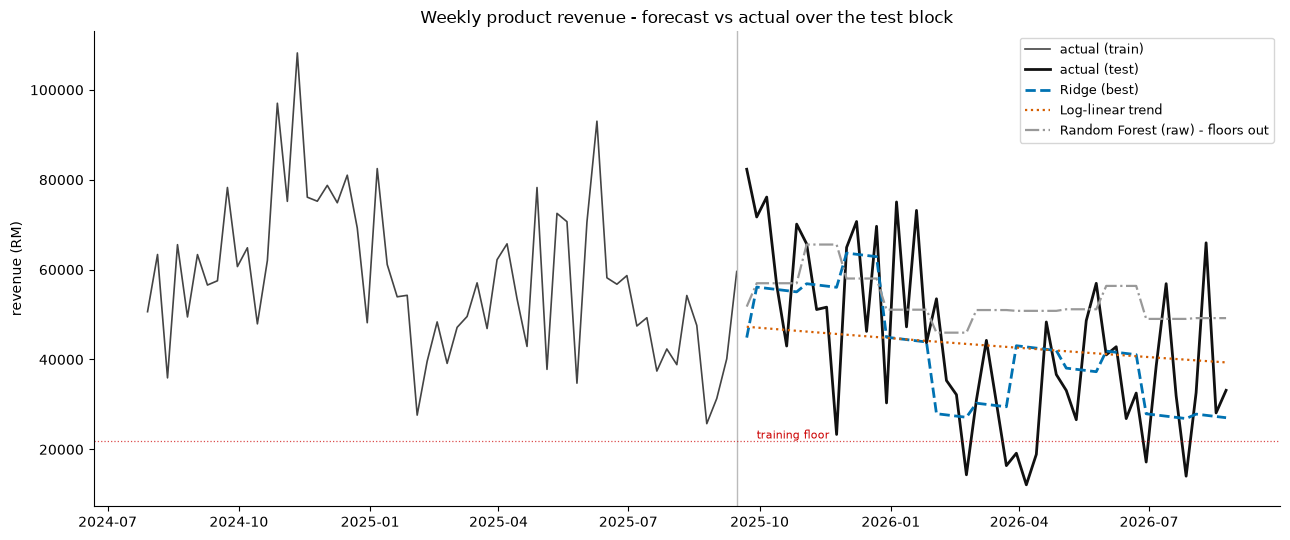

In [9]:
best = table.iloc[0]["model"]
baseline = "Log-linear trend"

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(train.weekStart.tail(60), train.revenue.tail(60), color="#444", lw=1.2, label="actual (train)")
ax.plot(test.weekStart, y_true, color="#111", lw=2.0, label="actual (test)")
ax.plot(test.weekStart, predictions[best], lw=2.0, ls="--", color="#0072B2", label=f"{best} (best)")
ax.plot(test.weekStart, predictions[baseline], lw=1.6, ls=":", color="#D55E00", label=baseline)
ax.plot(test.weekStart, predictions["Random Forest (raw)"], lw=1.6, ls="-.", color="#999",
        label="Random Forest (raw) - floors out")
ax.axvline(train.weekStart.iloc[-1], color="#bbb", lw=1)
ax.axhline(train.revenue.min(), color="#cc0000", lw=0.9, ls=":", alpha=0.7)
ax.text(test.weekStart.iloc[1], train.revenue.min() * 1.02, "training floor",
        color="#cc0000", fontsize=8)
ax.set_title("Weekly product revenue - forecast vs actual over the test block")
ax.set_ylabel("revenue (RM)")
ax.legend(loc="upper right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## The same forecast, read monthly

Weekly numbers for a shop this size are volatile - one rig build moves a week by a fifth.
Adding the weekly forecasts up into months averages that out, and is the fairer view of
whether the model is useful for planning. The model is unchanged; only the reporting bucket is.

In [10]:
monthly = (pd.DataFrame({"weekStart": test.weekStart.to_numpy(),
                         "actual": y_true,
                         "forecast": predictions[best]})
             .assign(month=lambda d: d.weekStart.dt.to_period("M").astype(str))
             .groupby("month")[["actual", "forecast"]].sum())
monthly = monthly.iloc[1:-1]   # first and last months are only part-covered by whole test weeks
monthly["error"] = monthly.forecast - monthly.actual
monthly["error%"] = monthly.error / monthly.actual * 100

wape_m = monthly.error.abs().sum() / monthly.actual.sum() * 100
display(monthly)
print(f"{best}:  weekly WAPE {table.iloc[0]['WAPE%']:.1f}%  ->  monthly WAPE {wape_m:.1f}%")

,actual,forecast,error,error%
month,,,,
2025-10,"245,849.0","221,799.5","-24,049.4",-9.8
2025-11,"191,819.0","225,861.6","34,042.6",17.7
2025-12,"281,871.8","298,070.2","16,198.4",5.7
2026-01,"239,202.1","177,171.3","-62,030.9",-25.9
2026-02,"135,348.2","110,149.7","-25,198.5",-18.6
2026-03,"141,184.9","162,576.2","21,391.2",15.2
2026-04,"116,024.1","169,600.2","53,576.2",46.2
2026-05,"165,305.1","150,727.9","-14,577.2",-8.8
2026-06,"160,435.4","193,805.7","33,370.4",20.8


Ridge:  weekly WAPE 29.2%  ->  monthly WAPE 17.4%


## What this run says

1. **Ridge on trend plus seasonality is the model to beat.** It is also the simplest thing
   here that can extrapolate, which is the property this series demands.
2. **Detrending fixes the forest.** Same algorithm, same features, same seed - only the target
   changed - and the error falls sharply. The raw version never once forecasts below its
   training floor, while the shop went below it seven times.
3. **`lag52` does not pay for itself.** The 52 training weeks it costs outweigh what a
   year-ago reading adds on a series whose year-on-year relationship is being broken by the
   price shock.
4. **Every model is forecasting a break it never saw.** The shock starts after the training
   period ends. The errors here are a floor on what is achievable, not evidence of a bad fit.

### Next

- Holt-Winters (ETS, damped trend) and ARIMA with Fourier terms, as the classical benchmarks.
- `TimeSeriesSplit` on the training block to tune `alpha` and the tree depths honestly.
- A `weeks_since_shock_start` feature. The RAM shortage was public news a shop owner would
  have known about, so it is legitimate exogenous information - but it must be declared in the
  report rather than slipped in.